# ms-eCPA stability and flash: a tutorial

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jmoortgat/CPA_and_eCPA_flash/blob/main/notebooks/ms_ecpa_flash_tutorial.ipynb)

This notebook shows how to use the stability and flash functions of the ms-eCPA package
(`multisalt/`, import name `ms_ecpa`). ms-eCPA is the ion-specific electrolyte
Cubic-Plus-Association equation of state for gases in water and in brines of
Na$^+$, K$^+$, Ca$^{2+}$, Mg$^{2+}$, Cl$^-$ and SO$_4^{2-}$.
The functions shown here are those of Paper III:

J. Moortgat, F. M. Coelho, A. Firoozabadi. Phase Equilibria of CO$_2$, CH$_4$, N$_2$, H$_2$,
C$_2$H$_6$, C$_3$H$_8$, and Mixtures in Multisalt Brines: Robust Stability and Flash Computations
with an Ion-Specific Electrolyte Cubic-Plus-Association Equation of State.
*Energy & Fuels* **2026**. [doi:10.1021/acs.energyfuels.6c04569](https://doi.org/10.1021/acs.energyfuels.6c04569)

The parameters of the model come from Paper II
([doi:10.1021/acs.energyfuels.6c04568](https://doi.org/10.1021/acs.energyfuels.6c04568)).
They are used here unchanged.

Each section has one to three short code cells, followed by a figure or a small table.
The examples use coarse grids, so the whole notebook runs in a few minutes with the
Python code, also on Google Colab.
The executable version of Paper III, with every figure and table, is
[`ms_ecpa_flash_paper.ipynb`](ms_ecpa_flash_paper.ipynb).

**Contents**

1. [Setup](#sec1)
2. [One stability-and-flash call](#sec2)
3. [The stability test along an isotherm](#sec3)
4. [Pressure scan: CO$_2$ in water and NaCl brine](#sec4)
5. [A gas mixture: CH$_4$–CO$_2$–H$_2$O and CH$_4$/CO$_2$ selectivity](#sec5)
6. [Three phases: vapor, brine and liquid CO$_2$](#sec6)
7. [Another gas: N$_2$](#sec7)
8. [Speed, and the 151,632-state flash grid](#sec8)
9. [Where to go next](#sec9)

<a id="sec1"></a>
## 1. Setup

The cell below prepares the environment. On Colab it clones the repository and installs
CoolProp. It then moves into the `multisalt/` directory and puts it, and its `scripts/`
folder, on the Python path. No installation of the package is needed.

The package has two implementations of the stability-and-flash call: the Python code and
an optional compiled Fortran library (`multisalt/fortran/`, built with `make -C fortran`).
Both give the same results. The cell uses the Fortran library when it has been built, and
the Python code otherwise (always on Colab).

In [1]:
# Setup: run this cell first (locally or on Google Colab).
import os, sys, subprocess

if "google.colab" in sys.modules and not os.path.exists("CPA_and_eCPA_flash"):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/jmoortgat/CPA_and_eCPA_flash.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "CoolProp"], check=True)

# work from the multisalt/ directory of the repository
for cand in ("CPA_and_eCPA_flash/multisalt", "../multisalt", "multisalt", "."):
    if os.path.exists(os.path.join(cand, "ms_ecpa", "parameters.py")):
        os.chdir(cand)
        break
sys.path[:0] = [os.getcwd(), os.path.join(os.getcwd(), "scripts")]

# use the compiled Fortran library when it has been built (make -C fortran)
built = os.listdir("fortran/build") if os.path.isdir("fortran/build") else []
if any(f.startswith("libecpa") for f in built):
    os.environ.setdefault("MS_ECPA_BACKEND", "fortran")

import ms_ecpa.backend as backend
if backend.mode() == "fortran" and not backend.available():
    backend.use("python")
print("working directory:", os.path.basename(os.getcwd()) + "/",
      "| backend:", backend.mode())

working directory: multisalt/ | backend: fortran


The next cell imports the functions used below, sets the figure style, and defines three
small helpers:

- `brine(...)` builds the vector of ion molalities [mol/kg water] in the order the package
  uses everywhere: Na$^+$, Cl$^-$, K$^+$, Ca$^{2+}$, Mg$^{2+}$, SO$_4^{2-}$.
- `molality(fr, i)` converts an aqueous mole fraction from a flash result into a
  molality [mol/kg water].
- `densities(fr, T, P)` returns the mass densities [kg/m3] of the two phases from the
  converged compressibility factors. The aqueous density includes the ion-specific
  Péneloux volume translation of Paper II, with the same expression as `ms_ecpa.eos`.

In [2]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({"font.size": 14, "axes.labelsize": 16, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12, "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold", "axes.linewidth": 1.6, "axes.edgecolor": "black", "xtick.major.width": 1.6, "ytick.major.width": 1.6, "xtick.major.size": 6, "ytick.major.size": 6, "xtick.color": "black", "ytick.color": "black", "xtick.direction": "in", "ytick.direction": "in", "lines.linewidth": 2.2, "lines.markersize": 7, "legend.frameon": True, "legend.edgecolor": "black"})
WONG = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
LINESTYLES = ["-", "--", "-.", ":", (0, (3, 1, 1, 1, 1, 1))]

from ms_ecpa import (stability_flash, michelsen_tpd, stability_flash3,
                     rachford_rice, wilson_k)
import ms_ecpa.parameters as prm

M_GAS = np.array([prm.Mw, prm.Mh, prm.Mc])     # kg/mol: H2O, CH4 slot, CO2


def brine(Na=0.0, Cl=0.0, K=0.0, Ca=0.0, Mg=0.0, SO4=0.0):
    # ion molalities [mol/kg water] in package order (Na, Cl, K, Ca, Mg, SO4)
    return np.array([Na, Cl, K, Ca, Mg, SO4], dtype=float)


def molality(fr, i):
    # molality [mol/kg water] of partitioning species i (0 H2O, 1 CH4, 2 CO2)
    return fr.x_aq[i] / (prm.Mw * fr.x_aq[0])


def densities(fr, T, P):
    # mass densities [kg/m3] of the aqueous and the gas-rich phase
    x, y = np.asarray(fr.x_aq), np.asarray(fr.y_gas)
    x_ion = prm.Mw * x[0] * np.asarray(fr.mi_aq)              # ion mole fractions
    pen = (prm.A_Peni * T / prm.Tc1 + prm.B_Peni) * 1e-6      # m3/mol
    v_aq = fr.Z_aq * prm.R * T / (P * 1e5) + x_ion @ pen
    rho_aq = (x @ M_GAS + x_ion @ prm.MMi) / v_aq
    rho_gas = P * 1e5 * (y @ M_GAS) / (fr.Z_gas * prm.R * T)
    return rho_aq, rho_gas

print("imports OK")

imports OK


<a id="sec2"></a>
## 2. One stability-and-flash call

`stability_flash(T, P, z, mi)` is the main entry point. Its arguments are

- `T`: temperature [K];
- `P`: pressure [bar];
- `z`: feed mole fractions of the three *partitioning* species, in the order
  (H$_2$O, CH$_4$, CO$_2$); they sum to 1, and the ions are not included;
- `mi`: the six ion molalities [mol/kg water].

The call first runs the tangent-plane-distance (TPD) stability test with eight trial
compositions (Paper III, Section 2.2). A water-rich feed ($z_{H_2O} \ge 0.9$) that this test finds stable is
tested again, with the gas trials against the brine at the feed composition; this second
test was added after Paper III (see `multisalt/PUBLISHED_VS_RELEASED.md`). When the most negative TPD is below the hard
threshold $-0.005$, it runs the $K$-value flash: accelerated successive substitution,
then a Newton polish (Section 2.3).

**Salinity convention.** By default `mi` is the molality of the ions in the equilibrium
aqueous phase ("as-aqueous"). This is how the experimental studies report their brines,
and it is the convention of every result in Papers II and III. The option
`salinity_convention="chain"` instead treats `mi` as the prepared brine and raises the
aqueous molality as water moves into the gas phase. The Fortran library implements only
the default; a `chain` call runs on the Python code.

Here: a feed of equal moles of water and CO$_2$ in a 1 mol/kg NaCl brine at 323.15 K
and 100 bar.

In [3]:
T, P = 323.15, 100.0                 # K, bar
z = np.array([0.5, 0.0, 0.5])        # H2O, CH4, CO2 (sums to 1; no ions)
mi = brine(Na=1.0, Cl=1.0)           # 1 mol/kg NaCl

r = stability_flash(T, P, z, mi)
fr = r.flash_result                  # None when the feed is single-phase

print("phases :", r.phases, "|", r.message)
print("tpd_min: %.4f" % r.tpd_min)
print("beta   : %.4f   (gas-rich phase fraction, partition basis)" % fr.beta)
print("solver : converged=%s, %d SSI + %d Newton iterations, max residual %.1e"
      % (fr.converged, fr.n_iter_ssi, fr.n_iter_newton, fr.max_residual))

rho_aq, rho_gas = densities(fr, T, P)
pd.DataFrame({"aqueous x": fr.x_aq, "gas-rich y": fr.y_gas, "K": fr.K},
             index=["H2O", "CH4", "CO2"]).style.format("{:.5g}")

phases : 2 | two-phase (trial K-init)
tpd_min: -0.5860
beta   : 0.4926   (gas-rich phase fraction, partition basis)
solver : converged=True, 8 SSI + 1 Newton iterations, max residual 9.4e-11


,aqueous x,gas-rich y,K
H2O,0.94916,0.0027275,0.0027753
CH4,0,0,nan
CO2,0.016638,0.99727,57.891


The result has three parts that you will use most:

- `r.phases` is 1 or 2, and `r.tpd_min` is the most negative TPD of the trials.
  `r.message` names the route that produced the answer, for example
  "two-phase (trial K-init)" when the flash started from the $K$-values of the best
  stability trial.
- `r.flash_result.x_aq` holds the *true* aqueous mole fractions of H$_2$O, CH$_4$ and
  CO$_2$. They do not sum to 1, because the ions take the rest.
  `r.flash_result.y_gas` holds the gas-rich phase, which contains no ions.
- `r.flash_result.K` holds the $K$-values on the *partition basis*: $K_i = y_i / x_i^{part}$,
  where $x^{part}$ is the aqueous composition with the ions removed and renormalized.

CH$_4$ is absent from this feed, so its entries are zero (and its $K$ is NaN).

The ions enter the flash only through one factor, $s = 1 - \sigma$, where $\sigma$ is the
total ion mole fraction of the brine (Paper III, Eq. 9). The cell below checks this, and
checks that the Rachford–Rice equation over the partitioning species alone (Eq. 8)
returns the reported $\beta$.

In [4]:
x = np.asarray(fr.x_aq)
x_ion = prm.Mw * x[0] * np.asarray(fr.mi_aq)        # x_j = M_H2O * m_j * x_H2O
s = 1.0 - x_ion.sum()
x_part = x / s

print("sum of all aqueous mole fractions  : %.12f" % (x.sum() + x_ion.sum()))
print("K from y / x_part (H2O, CO2)       :", np.round(np.asarray(fr.y_gas)[[0, 2]] / x_part[[0, 2]], 6))
print("rachford_rice(K, z) vs beta        : %.10f  %.10f" % (rachford_rice(fr.K, z), fr.beta))
print("Wilson K at (T, P), the cold start :", np.round(wilson_k(T, P), 4))
print("CO2 molality %.4f mol/kg | densities aq %.1f, gas %.1f kg/m3"
      % (molality(fr, 2), rho_aq, rho_gas))

sum of all aqueous mole fractions  : 1.000000000000
K from y / x_part (H2O, CO2)       : [2.7750000e-03 5.7891045e+01]
rachford_rice(K, z) vs beta        : 0.4926027940  0.4926027940
Wilson K at (T, P), the cold start : [1.6000e-03 4.2761e+00 1.0809e+00]
CO2 molality 0.9730 mol/kg | densities aq 1029.9, gas 370.0 kg/m3


The same call works for any brine: only `mi` changes. The table compares four brines at
the same state. The mixed brine is the five-ion recipe of Wang et al. (2014) used in the
flash grid of Section 8. The ionic strength is $I = \frac{1}{2}\sum_j m_j z_j^2$.

In [5]:
CHARGE = np.array([1, -1, 1, 2, 2, -2])
brines = {"water": brine(),
          "NaCl 1 m": brine(Na=1, Cl=1),
          "CaCl2 1 m": brine(Ca=1, Cl=2),
          "mixed (Wang 2014)": brine(Na=0.43, Cl=1.04, Ca=0.29, Mg=0.02, SO4=0.01)}
rows = []
for name, m in brines.items():
    f = stability_flash(T, P, z, m).flash_result
    ra, rg = densities(f, T, P)
    rows.append({"brine": name, "I [mol/kg]": 0.5 * m @ CHARGE**2,
                 "m_CO2 [mol/kg]": molality(f, 2), "y_H2O [-]": f.y_gas[0],
                 "rho_aq [kg/m3]": ra, "rho_gas [kg/m3]": rg})
pd.DataFrame(rows).set_index("brine").style.format("{:.4g}")

,I [mol/kg],m_CO2 [mol/kg],y_H2O [-],rho_aq [kg/m3],rho_gas [kg/m3]
brine,,,,,
water,0,1.246,0.002826,999,370.1
NaCl 1 m,1,0.973,0.002728,1030,370
CaCl2 1 m,3,0.8354,0.002656,1067,369.9
mixed (Wang 2014),1.375,0.9705,0.002737,1034,370


Salt lowers the CO$_2$ molality (salting-out) and raises the brine density. At the same
molality, CaCl$_2$ salts out more than NaCl because its ionic strength is three times
larger. The water content of the gas-rich phase also drops slightly, because salt lowers
the activity of water.

<a id="sec3"></a>
## 3. The stability test along an isotherm

`michelsen_tpd(z, mi, T, P)` runs the stability test alone. Note the argument order:
the feed and the brine come first, then `T` [K] and `P` [bar]. It returns a
`StabilityResult` with

- `tpd_min`: the most negative TPD over the trials that did not return to the feed
  composition (0 when no trial is negative);
- `trials`: one `TPDResult` per trial, with its `label`, converged composition `w`,
  `tpd` and `converged` flag;
- `stable`: the verdict.

The TPD is Michelsen's $tm^\star = 1 - \sum_i W_i$ at a stationary point (Paper III, Eq. 5).
A negative value means that the feed can lower its Gibbs energy by splitting, so a second
phase exists.

The example follows Figure S1 of Paper III: a feed with $z_{CO_2} = 0.6$ in a 1 mol/kg
NaCl brine, along three isotherms. At high temperature and low pressure all the water
evaporates and the feed is a single vapor phase. As pressure rises, the water condenses
and a brine phase appears. To show the stable side as well, the helper below takes the
lowest TPD over the *non-trivial* trials, which is positive when the feed is stable.

In [6]:
def tpd_nontrivial(st, z, atol=5e-3):
    # lowest TPD over converged trials whose composition differs from the feed
    vals = [t.tpd for t in st.trials
            if t.converged and np.max(np.abs(np.asarray(t.w) - z)) > atol]
    return min(vals) if vals else np.nan

z6 = np.array([0.4, 0.0, 0.6])
mi1 = brine(Na=1.0, Cl=1.0)
P_scan = np.geomspace(2.0, 300.0, 14)
T_iso = (373.15, 423.15, 473.15)

t0 = time.perf_counter()
tpd = {T_: [tpd_nontrivial(michelsen_tpd(z6, mi1, T_, P_), z6) for P_ in P_scan] for T_ in T_iso}
print("%d stability tests in %.1f s" % (len(T_iso) * len(P_scan), time.perf_counter() - t0))

42 stability tests in 3.0 s


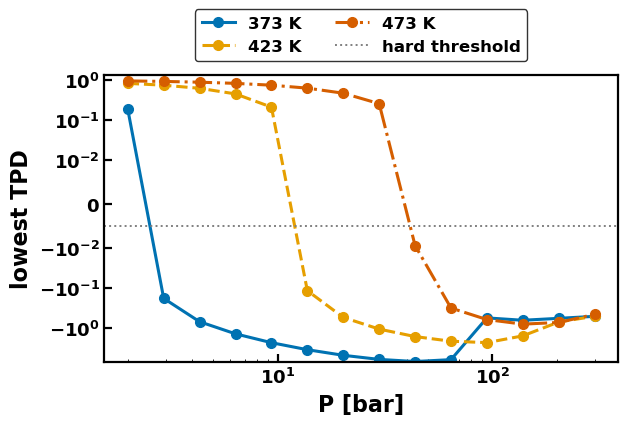

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, T_ in enumerate(T_iso):
    ax.plot(P_scan, tpd[T_], color=WONG[[5, 1, 6][k]], ls=LINESTYLES[k], marker="o", label="%.0f K" % T_)
ax.axhline(-0.005, color="gray", lw=1.4, ls=":", label="hard threshold")
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=0.01)
ax.set_xlabel("P [bar]")
ax.set_ylabel("lowest TPD")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2)
plt.tight_layout(); plt.show()

Positive values (top) mean a stable single vapor phase; the feed is unstable below the
dotted line. The sign change marks the dew point of the feed: near 2.5 bar at 373 K,
12 bar at 423 K and 40 bar at 473 K. A simple check: water condenses when its partial
pressure, 0.4 $P$, reaches the vapor pressure of water (1.0, 4.8 and 15.5 bar at these
temperatures).
The vertical axis is linear between $-0.01$ and $0.01$ and logarithmic outside.

The magnitude of a negative TPD has no physical meaning beyond its sign. Only the
classification (and the pressure at which the sign changes) is used.

<a id="sec4"></a>
## 4. Pressure scan: CO$_2$ in water and NaCl brine

A pressure scan is a loop over `stability_flash`. In the two-phase region the phase
compositions depend only on $T$, $P$ and the brine, not on the feed, so one CO$_2$-rich
feed traces the whole curve.

The CO$_2$ content of the brine is shown on the *salt-free* basis,
$x_{CO_2}^{sf} = x_{CO_2}/(x_{H_2O} + x_{CO_2})$, computed from the true mole fractions, which is how the
measurements are reported. The measurements are from GasBrineBench, loaded with
`load_experimental` from `scripts/data_loader.py` (on the first call the package fetches
the pinned GasBrineBench release into `~/.cache/ecpa/`).

In [8]:
from data_loader import load_experimental
exp_w = load_experimental("binaries_co2_water")      # CO2 + H2O
exp_b = load_experimental("co2_brines")              # CO2 + single-salt brines

T4 = 323.0
P4 = np.array([5, 10, 20, 40, 60, 80, 100, 150, 200, 300, 400, 600], dtype=float)
m4 = (0.0, 1.0, 3.0)                                 # mol/kg NaCl
scan = {}
for m in m4:
    xs, ys = [], []
    for P_ in P4:
        rr = stability_flash(T4, P_, np.array([0.5, 0.0, 0.5]), brine(Na=m, Cl=m))
        f = rr.flash_result
        ok = rr.phases == 2 and f is not None and f.converged
        xs.append(f.x_aq[2] / (f.x_aq[0] + f.x_aq[2]) if ok else np.nan)
        ys.append(f.y_gas[0] if ok else np.nan)
    scan[m] = (np.array(xs), np.array(ys))

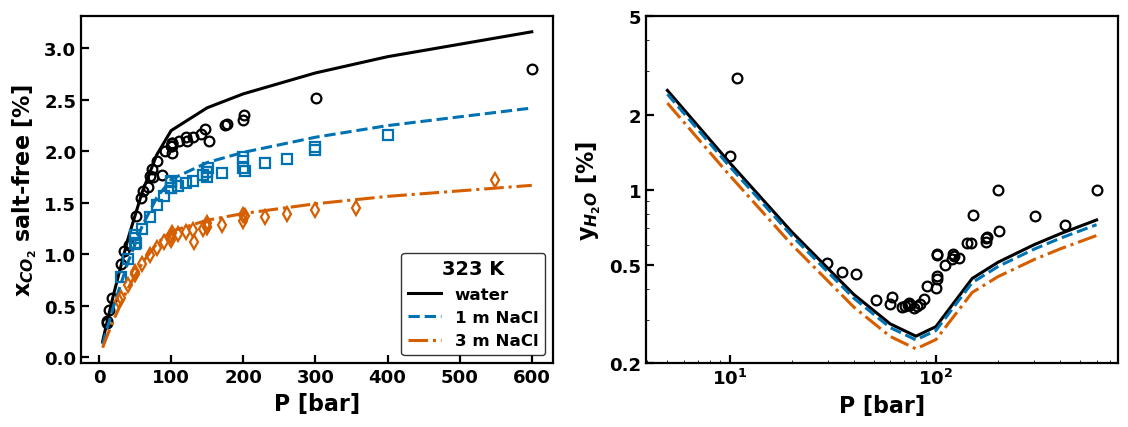

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
for k, m in enumerate(m4):
    c, ls = WONG[[0, 5, 6][k]], LINESTYLES[k]
    lab = "water" if m == 0 else "%.0f m NaCl" % m
    axes[0].plot(P4, 100 * scan[m][0], color=c, ls=ls, label=lab)
    axes[1].plot(P4, 100 * scan[m][1], color=c, ls=ls, label=lab)
    if m == 0:
        e = exp_w[np.isclose(exp_w.T_K, T4, atol=0.6) & (exp_w.P_bar <= 600)]
        axes[0].plot(e.P_bar, 100 * e.x_CO2_aq_exp, "o", mfc="none", mew=1.6, color=c)
        axes[1].plot(e.P_bar, 100 * e.y_H2O_gas_exp, "o", mfc="none", mew=1.6, color=c)
    else:
        e = exp_b[(exp_b.salt == "NaCl") & np.isclose(exp_b.T_K, T4, atol=0.6)
                  & np.isclose(exp_b.ms_mol_kg, m, atol=0.05) & (exp_b.P_bar <= 600)]
        axes[0].plot(e.P_bar, 100 * e.xc_W, "sd"[k - 1], mfc="none", mew=1.6, color=c)
axes[0].set(xlabel="P [bar]", ylabel="x$_{CO_2}$ salt-free [%]")
axes[1].set(xlabel="P [bar]", ylabel="y$_{H_2O}$ [%]", xscale="log", yscale="log")
axes[1].set_yticks([0.2, 0.5, 1, 2, 5], ["0.2", "0.5", "1", "2", "5"])
axes[0].legend(loc="lower right", title="323 K")
plt.tight_layout(); plt.show()

Lines are ms-eCPA, open symbols are measurements at 323 K. Left: CO$_2$ solubility rises
steeply up to the CO$_2$ saturation region near 80 bar and then levels off; each mol/kg of
NaCl lowers it. Right: the water content of the CO$_2$-rich phase falls with pressure,
passes through a minimum, and rises again as the CO$_2$ becomes dense. Only salt-free
measurements exist for the gas-phase water content. Above about 80 bar the computed water
content is below the measurements; Paper III (Section 3.4) quantifies this low bias of the
dense CO$_2$-rich phase below 350 K.

Paper III, Table 1, scores the same flash against all 1931 single-salt CO$_2$–brine
measurements (AARE 6.55%).

<a id="sec5"></a>
## 5. A gas mixture: CH$_4$–CO$_2$–H$_2$O and CH$_4$/CO$_2$ selectivity

With both gases in the feed, `z` has three non-zero entries. No parameter of ms-eCPA is
fitted to ternary data. The only CH$_4$–CO$_2$ parameter is the constant
$k_{hc} = 0.080$ (Paper III, Section 2.1).

The ternary measurements are reported against the water-free CO$_2$ fraction of the gas,
$Y_{CO_2} = y_{CO_2}/(y_{CH_4} + y_{CO_2})$. The helper below sets the feed from a target
$Y_{CO_2}$ and a total gas fraction `zg`. If the split is degenerate ($\beta$ within
0.001 of 0 or 1) it retries with other values of `zg`, as the scripts of Paper III do
(`scripts/fig_ccw_ternary.py`). The plotted $Y_{CO_2}$ is the one of the computed gas
phase.

In [10]:
def flash_ternary(T, P, Yc, mi, zgs=(0.20, 0.30, 0.10, 0.50, 0.05)):
    # stability_flash for a CH4-CO2-H2O(-brine) feed with water-free gas fraction Yc
    for zg in zgs:
        zz = np.array([1.0 - zg, zg * (1.0 - Yc), zg * Yc])
        rr = stability_flash(T, P, zz, mi)
        f = rr.flash_result
        if rr.phases == 2 and f is not None and f.converged and 1e-3 < f.beta < 1 - 1e-3:
            return f
    return None

exp_t = load_experimental("ccw_ternary")
T5, P5 = 344.0, (100.0, 500.0)                      # isotherm of Dhima et al. (1999)
Yc_grid = np.linspace(0.05, 0.95, 9)
tern = {}
for P_ in P5:
    fs = [flash_ternary(T5, P_, Yc, brine()) for Yc in Yc_grid]
    tern[P_] = pd.DataFrame([{"Yc": f.y_gas[2] / (f.y_gas[1] + f.y_gas[2]),
                              "x_CH4": f.x_aq[1], "x_CO2": f.x_aq[2]} for f in fs if f is not None])

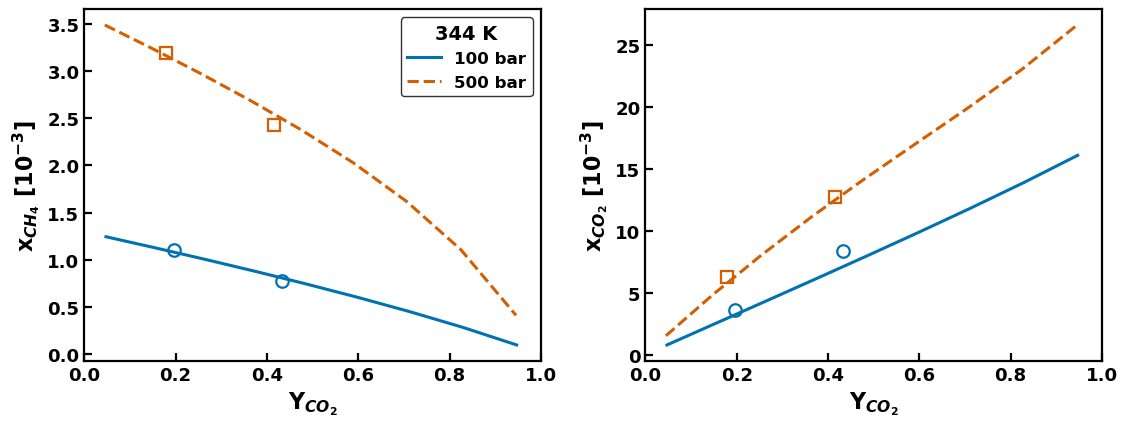

aqueous CH4 at 344 K: AARE 3.8% over 9 states
aqueous CO2 at 344 K: AARE 14.7% over 9 states


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
for k, P_ in enumerate(P5):
    c, ls, mk = WONG[[5, 6][k]], LINESTYLES[k], "os"[k]
    d = tern[P_]
    e = exp_t[(exp_t.T_K == T5) & (exp_t.P_bar == P_)]
    for ax, col, ecol in ((axes[0], "x_CH4", "x_CH4_aq_exp"), (axes[1], "x_CO2", "x_CO2_aq_exp")):
        ax.plot(d.Yc, 1e3 * d[col], color=c, ls=ls, label="%.0f bar" % P_)
        ax.plot(e.Yc_gas, 1e3 * e[ecol], mk, mfc="none", mew=1.6, ms=9, color=c)
axes[0].set(xlabel="Y$_{CO_2}$", ylabel="x$_{CH_4}$ [10$^{-3}$]", xlim=(0, 1))
axes[1].set(xlabel="Y$_{CO_2}$", ylabel="x$_{CO_2}$ [10$^{-3}$]", xlim=(0, 1))
axes[0].legend(loc="upper right", title="344 K")
plt.tight_layout(); plt.show()

# score the flash at every measured state of this isotherm
e = exp_t[exp_t.T_K == T5]
pred = [flash_ternary(T5, rw.P_bar, rw.Yc_gas, brine()) for rw in e.itertuples()]
ok = np.array([f is not None for f in pred])
for name, i, col in (("CH4", 1, "x_CH4_aq_exp"), ("CO2", 2, "x_CO2_aq_exp")):
    p = np.array([f.x_aq[i] for f in pred if f is not None])
    print("aqueous %s at 344 K: AARE %.1f%% over %d states" % (name, 100 * np.mean(np.abs(p / e[col].to_numpy()[ok] - 1)), ok.sum()))

Aqueous CH$_4$ falls and aqueous CO$_2$ rises as the gas becomes richer in CO$_2$. Both
grow with pressure. Symbols are the measurements of Dhima et al. (1999) at the same
pressures. Paper III (Section 3.3 and Table S9) reports the same comparison with the same
route: an AARE of 3.8% for aqueous CH$_4$ at 344 K.

**Selectivity in brine.** The CO$_2$/CH$_4$ selectivity is the ratio of the two
$K$-values, $\alpha = (y_{CO_2}/x_{CO_2}) / (y_{CH_4}/x_{CH_4})$. A value below 1 means
that the brine takes up CO$_2$ in preference to CH$_4$. The cell computes $\alpha$ at
323 K and 300 bar, the state of Paper III, Section S13, for water and three brines.
No mixed-gas measurement in brine exists, so these values are predictions.

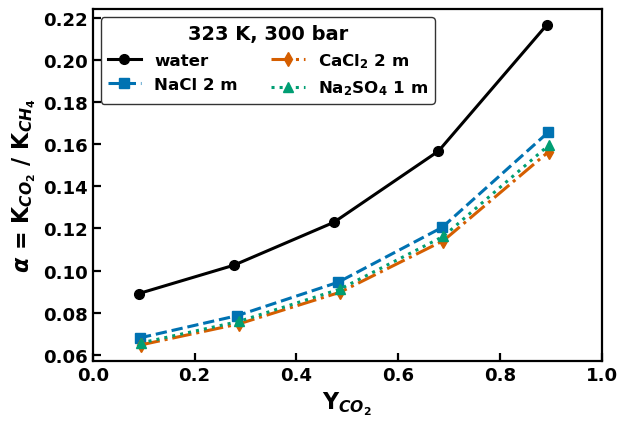

In [12]:
T5b, P5b = 323.0, 300.0
Yc_sel = np.linspace(0.1, 0.9, 5)
sel_brines = {"water": brine(), "NaCl 2 m": brine(Na=2, Cl=2),
              "CaCl$_2$ 2 m": brine(Ca=2, Cl=4), "Na$_2$SO$_4$ 1 m": brine(Na=2, SO4=1)}
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, (name, m) in enumerate(sel_brines.items()):
    fs = [flash_ternary(T5b, P5b, Yc, m) for Yc in Yc_sel]
    a = [(f.y_gas[2] / f.x_aq[2]) / (f.y_gas[1] / f.x_aq[1]) for f in fs if f is not None]
    Y = [f.y_gas[2] / (f.y_gas[1] + f.y_gas[2]) for f in fs if f is not None]
    ax.plot(Y, a, color=WONG[[0, 5, 6, 3][k]], ls=LINESTYLES[k], marker="osd^"[k], label=name)
ax.set(xlabel="Y$_{CO_2}$", ylabel=r"$\alpha$ = K$_{CO_2}$ / K$_{CH_4}$", xlim=(0, 1))
ax.legend(loc="upper left", title="323 K, 300 bar", ncol=2)
plt.tight_layout(); plt.show()

$\alpha$ lies between about 0.06 and 0.22: the water takes up CO$_2$ in preference to
CH$_4$ by a factor of 5 to 15, most strongly when the gas is rich in CH$_4$. Salt lowers
$\alpha$ further, because it lowers the solubility of CH$_4$ more than that of CO$_2$.
The three brines give nearly the same $\alpha$.

<a id="sec6"></a>
## 6. Three phases: vapor, brine and liquid CO$_2$

Below the CO$_2$ critical temperature (304.13 K), a vapor, the brine and a CO$_2$-rich
liquid can coexist. `stability_flash3(T, P, z, mi)` takes the same arguments as
`stability_flash`. It runs the two-phase computation first, tests the converged two-phase
state for a third phase with trials on the other density root, and runs the three-phase
flash when a trial is below the tangent plane (Paper III, Section 2.4).
`stability_flash3` always uses the Python code.

The result has `phases` (1, 2 or 3), `two_phase` (the first-stage result), `tpd3_min`, and
`flash3` with the phase fractions `beta_g` (vapor) and `beta_l` (CO$_2$-rich liquid) and
the compositions `x_aq`, `y_gas` and `x_lco2`.

The example is the feed of Paper III, Section 3.4: $z$ = 0.50/0.03/0.47
(H$_2$O/CH$_4$/CO$_2$) at 283.15 K and 56 bar. A little CH$_4$ turns the three-phase
line of the CO$_2$–H$_2$O binary into a pressure interval.

In [13]:
z3 = np.array([0.50, 0.03, 0.47])
r3 = stability_flash3(283.15, 56.0, z3, brine())
f3 = r3.flash3
print("phases:", r3.phases, "|", r3.message, "| tpd3_min = %.4f" % r3.tpd3_min)
print("beta_g = %.4f (vapor), beta_l = %.4f (liquid CO2), max residual %.1e"
      % (f3.beta_g, f3.beta_l, f3.max_residual))
pd.DataFrame({"aqueous": f3.x_aq, "vapor": f3.y_gas, "liquid CO2": f3.x_lco2},
             index=["H2O", "CH4", "CO2"]).style.format("{:.4g}")

phases: 3 | three-phase (V + Laq + L_CO2) | tpd3_min = -0.0626
beta_g = 0.0922 (vapor), beta_l = 0.3949 (liquid CO2), max residual 2.6e-10


,aqueous,vapor,liquid CO2
H2O,0.9749,0.0002337,7.97e-05
CH4,0.0003104,0.1433,0.0421
CO2,0.02484,0.8565,0.9578


The vapor is enriched in CH$_4$ (14%), the CO$_2$-rich liquid holds 4% CH$_4$, and the
brine holds 2.5% CO$_2$. With salt in the feed the three-phase state persists, and the
aqueous CO$_2$ falls. The table gives the aqueous CO$_2$ (salt-free basis) relative to
water. These are predictions: no three-phase measurement in brine exists.

In [14]:
salts3 = {"water": brine(), "NaCl 1 m": brine(Na=1, Cl=1), "NaCl 3 m": brine(Na=3, Cl=3),
          "KCl 1 m": brine(K=1, Cl=1), "CaCl2 1 m": brine(Ca=1, Cl=2)}
rows = []
for name, m in salts3.items():
    q = stability_flash3(283.15, 56.0, z3, m)
    x = q.flash3.x_aq if q.phases == 3 else q.two_phase.flash_result.x_aq
    rows.append({"brine": name, "phases": q.phases, "x_CO2 salt-free": x[2] / (x[0] + x[2])})
tab3 = pd.DataFrame(rows).set_index("brine")
tab3["ratio to water"] = tab3["x_CO2 salt-free"] / tab3.loc["water", "x_CO2 salt-free"]
tab3.style.format({"x_CO2 salt-free": "{:.5f}", "ratio to water": "{:.2f}"})

,phases,x_CO2 salt-free,ratio to water
brine,,,
water,3,0.02484,1.00
NaCl 1 m,3,0.01910,0.77
NaCl 3 m,3,0.01312,0.53
KCl 1 m,3,0.02084,0.84
CaCl2 1 m,3,0.01760,0.71


Paper III (Section 3.4) gives the ratios 0.77, 0.53, 0.84 and 0.71 for 1 and 3 mol/kg
NaCl, 1 mol/kg KCl and 1 mol/kg CaCl$_2$.

**The three-phase pressure of CO$_2$–H$_2$O.** For the salt-free binary the three phases
coexist only on a line $P_3(T)$. Below $P_3$ the dense (liquid-CO$_2$) trial lies above the
tangent plane of the vapor–brine split; above $P_3$ it lies below. The script
`pilot_studies/three_phase_2026_08/vlle_locus.py` finds $P_3$ as the root of this signed
TPD; its functions are reused here at three temperatures. The reference is the
saturation pressure of pure CO$_2$ from the Span–Wagner equation of state (CoolProp),
which the measured three-phase pressures follow within a few tenths of a bar.

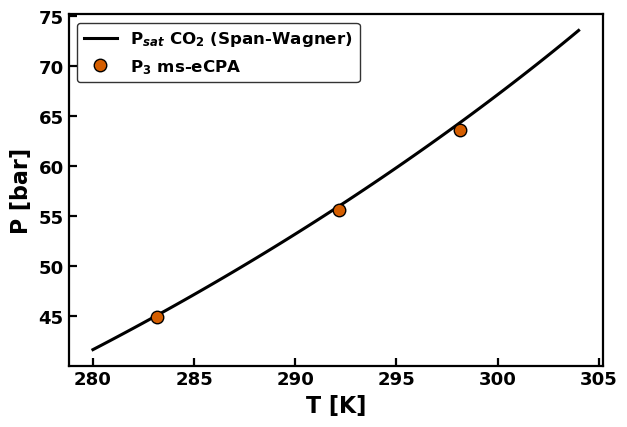

,T [K],P3 ms-eCPA [bar],Psat CO2 [bar],dP [bar]
0,283.15,44.84,45.02,-0.18
1,292.15,55.56,55.96,-0.40
2,298.15,63.63,64.34,-0.71


In [15]:
sys.path.insert(0, os.path.join(os.getcwd(), "pilot_studies", "three_phase_2026_08"))
import vlle_locus                        # locus_indicator(T, P), locate_p3(T, p_lo, p_hi)
from CoolProp.CoolProp import PropsSI

rows = []
for T_ in (283.15, 292.15, 298.15):
    psat = PropsSI("P", "T", T_, "Q", 0, "CO2") / 1e5
    p3 = vlle_locus.locate_p3(T_, psat - 3.0, psat + 3.0, n_scan=4)
    rows.append({"T [K]": T_, "P3 ms-eCPA [bar]": p3, "Psat CO2 [bar]": psat, "dP [bar]": p3 - psat})
loc = pd.DataFrame(rows)

Ts = np.linspace(280.0, 304.0, 60)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(Ts, [PropsSI("P", "T", t, "Q", 0, "CO2") / 1e5 for t in Ts], color=WONG[0], ls="-", label="P$_{sat}$ CO$_2$ (Span-Wagner)")
ax.plot(loc["T [K]"], loc["P3 ms-eCPA [bar]"], "o", color=WONG[6], mec="black", ms=9, ls="none", label="P$_3$ ms-eCPA")
ax.set(xlabel="T [K]", ylabel="P [bar]")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
loc.style.format("{:.2f}")

The computed three-phase pressure lies a few tenths of a bar below the CO$_2$ saturation
pressure, and the gap grows toward the CO$_2$ critical point. Paper III (Figure 6) reports
0.2–1.1 bar over 283–302 K; the shipped file `vlle_locus.csv` holds the published values
(44.84 bar at 283.15 K, 55.56 bar at 292.15 K, 63.63 bar at 298.15 K).

<a id="sec7"></a>
## 7. Another gas: N$_2$

The package has two gas slots: CH$_4$ (slot 2) and CO$_2$ (slot 3). N$_2$, H$_2$,
C$_2$H$_6$ and C$_3$H$_8$ (Paper III, Section 3.2) are computed by replacing the CH$_4$
parameters with those of the other gas while the program runs. The package files are not
changed. The pilot study `pilot_studies/n2_pilot_2026_07/n2_pilot.py` does this for N$_2$:

- `rebind_n2(Ak, Bk, Ck, s_nacl)` sets the N$_2$ critical constants, its polarizability,
  the N$_2$–H$_2$O binary parameter $k_{ij}(T)$ (coefficients `Ak, Bk, Ck` of Paper III,
  Eq. 3) and the N$_2$–ion energies. The ion energies are the CH$_4$ values with the slope
  scaled by $T_{c,N_2}/T_{c,CH_4}$ (`s_nacl = 1` keeps this transfer unchanged);
- `restore_ch4()` puts the production CH$_4$ parameters back;
- `_predict_point(task)` does both around one `stability_flash` call and returns the
  aqueous N$_2$ mole fraction on the basis of O'Sullivan and Smith (1970), which counts
  NaCl as one undissociated component.

The fitted $k_{ij}$ coefficients are read from the pilot result file `n2_results.json`.
The compiled Fortran library holds its own copy of the parameters, so while N$_2$ is bound
the calls go to the Python code; the package does this automatically.

In [16]:
import json
sys.path.insert(0, os.path.join(os.getcwd(), "pilot_studies", "n2_pilot_2026_07"))
import n2_pilot

with open("pilot_studies/n2_pilot_2026_07/n2_results.json") as fh:
    kij = json.load(fh)["fitB"]["best"]["x"]          # (Ak, Bk, Ck) of the N2-H2O k_ij(T)
print("N2-H2O k_ij coefficients:", np.round(kij, 4))

def x_n2(T, P_bar, m_nacl):
    # aqueous N2 mole fraction (NaCl-undissociated basis); the CH4 slot is restored on return
    return n2_pilot._predict_point((*kij, 1.0, n2_pilot.POL_N2, T, P_bar, m_nacl))

exp_n2 = n2_pilot.load_n2()                           # O'Sullivan & Smith (1970), 51 points
ref_before = n2_pilot.guard_spot("ch4_nacl")          # a CH4 flash before any rebinding
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # "compiled kernel not used" notice
    exp_n2["x_pred"] = [x_n2(rw.T_K, rw.P_atm * n2_pilot.ATM_TO_BAR, rw.m_NaCl_mol_kg)
                        for rw in exp_n2.itertuples()]
    P7 = np.geomspace(90.0, 650.0, 8)                  # bar
    T7 = 324.65
    curves = {m: [x_n2(T7, p, m) for p in P7] for m in (0.0, 1.0, 4.0)}

N2-H2O k_ij coefficients: [ 5.5159 -3.9679  0.466 ]


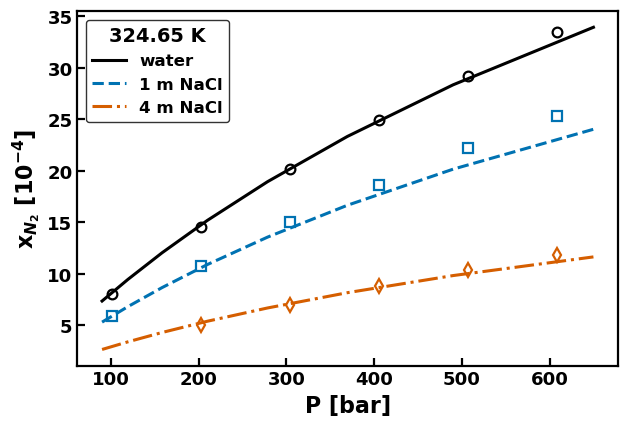

AARE water: 1.09% (18 points) | AARE brine: 3.65% (33 points)
CH4 slot restored: True | parameters equal to the compiled set: True


In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k, m in enumerate((0.0, 1.0, 4.0)):
    c = WONG[[0, 5, 6][k]]
    lab = "water" if m == 0 else "%.0f m NaCl" % m
    ax.plot(P7, 1e4 * np.array(curves[m]), color=c, ls=LINESTYLES[k], label=lab)
    e = exp_n2[np.isclose(exp_n2.T_K, T7) & np.isclose(exp_n2.m_NaCl_mol_kg, m)]
    ax.plot(e.P_atm * n2_pilot.ATM_TO_BAR, 1e4 * e.x_molefrac, "osd"[k], mfc="none", mew=1.6, color=c)
ax.set(xlabel="P [bar]", ylabel="x$_{N_2}$ [10$^{-4}$]")
ax.legend(loc="upper left", title="%.2f K" % T7)
plt.tight_layout(); plt.show()

err = 100 * np.abs(exp_n2.x_pred / exp_n2.x_molefrac - 1)
print("AARE water: %.2f%% (%d points) | AARE brine: %.2f%% (%d points)"
      % (err[exp_n2.m_NaCl_mol_kg == 0].mean(), (exp_n2.m_NaCl_mol_kg == 0).sum(),
         err[exp_n2.m_NaCl_mol_kg > 0].mean(), (exp_n2.m_NaCl_mol_kg > 0).sum()))
print("CH4 slot restored:", n2_pilot.tuples_bit_identical(ref_before, n2_pilot.guard_spot("ch4_nacl")),
      "| parameters equal to the compiled set:", backend._drifted_parameter() is None)

The salt-free points fix the N$_2$–H$_2$O binary parameter. The brine curves are
predictions: no parameter was fitted to N$_2$-in-brine data. Paper III (Section 3.2)
reports AAREs of 1.09% in water (18 points) and 3.66% in brine (33 points), which the cell
reproduces. The last line checks that the CH$_4$ slot is back to its production values:
a CH$_4$ flash gives bit-identical results before and after, and the Python parameters
again equal those of the compiled library.

H$_2$ works the same way through `pilot_studies/h2_pilot_2026_07/h2_pilot.py`, and
C$_2$H$_6$ and C$_3$H$_8$ through the `c2_pilot_*` and `c3_pilot_*` folders.
`scripts/fig_additional_gases.py` shows how the paper figures use them.

<a id="sec8"></a>
## 8. Speed, and the 151,632-state flash grid

`ms_ecpa.backend.use("python")` or `use("fortran")` switches the implementation behind
`stability_flash` for the running process. The environment variable `MS_ECPA_BACKEND`
sets it at start-up. The cell times the same batch of two-phase states (CO$_2$ in
1 mol/kg NaCl) with each implementation that is available. The Fortran library returns
the same results. Its result object has no `route` field and leaves `stability` and
`attempts` empty, so read `message` for the route. Only `stability_flash` has a compiled
version; `michelsen_tpd`, `flash_kv` and `stability_flash3` always run in Python.

In [18]:
rng = np.random.default_rng(1)
batch = [(rng.uniform(300, 450), rng.uniform(20, 400)) for _ in range(30)]
zb, mb = np.array([0.5, 0.0, 0.5]), brine(Na=1, Cl=1)

def run_batch():
    t0 = time.perf_counter()
    out = [stability_flash(T_, P_, zb, mb).flash_result.x_aq[2] for T_, P_ in batch]
    return np.array(out), time.perf_counter() - t0

start_mode = backend.mode()
modes = ["python"] + (["fortran"] if backend.available() else [])
res = {}
for mode in modes:
    backend.use(mode)
    res[mode] = run_batch()
    print("%-8s %d calls in %6.2f s  (%.2f ms per call)" % (mode, len(batch), res[mode][1], 1e3 * res[mode][1] / len(batch)))
backend.use(start_mode)
if "fortran" in res:
    print("speed-up %.0fx; largest relative difference in x_CO2: %.1e"
          % (res["python"][1] / res["fortran"][1], np.max(np.abs(res["fortran"][0] / res["python"][0] - 1))))

python   30 calls in   9.73 s  (324.37 ms per call)
fortran  30 calls in   0.06 s  (1.95 ms per call)
speed-up 167x; largest relative difference in x_CO2: 8.6e-14


Paper III (Section 3.5) ran `stability_flash` over 151,632 states: 283–623 K, 1–1000 bar,
eight salt configurations, and three feed families (CO$_2$–H$_2$O, CH$_4$–H$_2$O and
CH$_4$–CO$_2$–H$_2$O) with three feeds each. The grid runs on a cluster
(`sweep/README.md`); its results are shipped in `results_cache/sweep/merged.parquet`, one
row per state. The columns include the inputs (`T_K`, `P_bar`, `z_*`, `m_*`,
`salt_name`, `feed_family`), the outcome (`phases`, `tpd_min`, `converged`,
`solve_path`), the phase compositions, densities, iteration counts and timings.

The cell reads a few columns and maps the aqueous CO$_2$ mole fraction and the number of
SSI iterations over $(T, P)$, for the CO$_2$–H$_2$O feed $z_{CO_2} = 0.5$ in 1 mol/kg NaCl.
Grey cells are single-phase.

151632 states, 151632 converged, 81787 two-phase


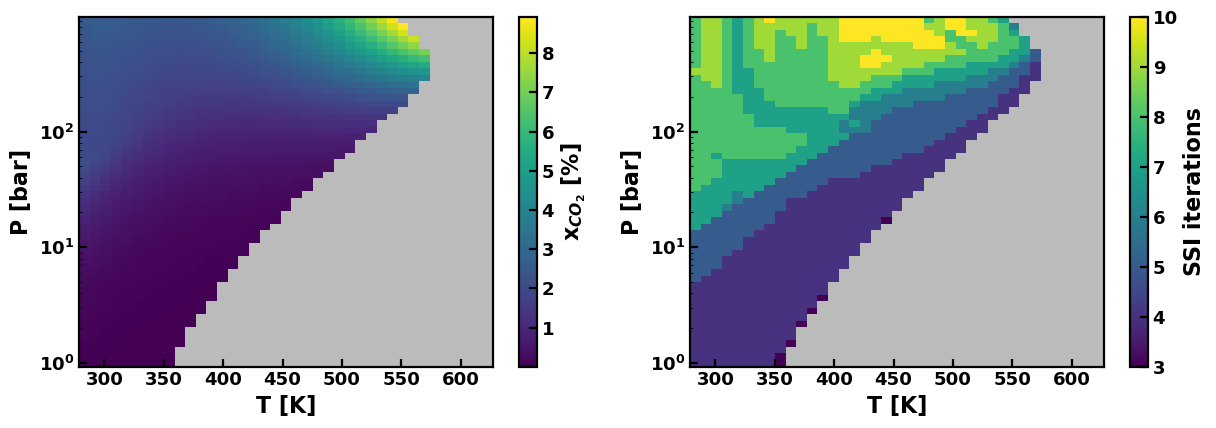

In [19]:
cols = ["feed_family", "salt_name", "T_K", "P_bar", "z_CO2", "phases", "converged",
        "x_CO2_aq", "n_iter_ssi"]
grid = pd.read_parquet("results_cache/sweep/merged.parquet", columns=cols)
print("%d states, %d converged, %d two-phase" % (len(grid), grid.converged.sum(), (grid.phases == 2).sum()))

sub = grid[(grid.feed_family == "binary_CO2") & (grid.salt_name == "NaCl_1m") & np.isclose(grid.z_CO2, 0.5)]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
for ax, col, scale, lab in ((axes[0], "x_CO2_aq", 100, "x$_{CO_2}$ [%]"), (axes[1], "n_iter_ssi", 1, "SSI iterations")):
    v = sub.assign(val=np.where(sub.phases == 2, scale * sub[col], np.nan)).pivot(index="P_bar", columns="T_K", values="val")
    cm = mpl.colormaps["viridis"].copy(); cm.set_bad("#bbbbbb")
    pc = ax.pcolormesh(v.columns, v.index, np.ma.masked_invalid(v.values), cmap=cm, shading="nearest")
    cb = fig.colorbar(pc, ax=ax); cb.set_label(lab, fontweight="bold")
    ax.set(xlabel="T [K]", ylabel="P [bar]", yscale="log")
plt.tight_layout(); plt.show()

Left: the CO$_2$ solubility grows with pressure and, at high pressure, also with
temperature above about 400 K. The grey region at high temperature and low pressure is a
single vapor phase: all the water evaporates. Above about 575 K the feed is single-phase at
every pressure of the grid. Right: two-phase states need 3 to 10 accelerated SSI iterations
before the Newton polish; Paper III, Table 4, gives a mean of 6.1 over the whole grid. The
count is lowest at low pressure and highest at high pressure and temperature, where the two
phases become more alike.

The same pattern selects any other quantity, salt or feed: `salt_name` takes the values
`no_salt`, `NaCl_0p5m`, `NaCl_1m`, `NaCl_3m`, `KCl_1m`, `KCl_3m`, `mix_LIU2011_B1` and
`mix_WANG2014_B1`.

<a id="sec9"></a>
## 9. Where to go next

- **Executable papers.** [`ms_ecpa_flash_paper.ipynb`](ms_ecpa_flash_paper.ipynb) has the
  full text of Paper III and regenerates its figures and tables.
  [`ms_ecpa_parametrization_paper.ipynb`](ms_ecpa_parametrization_paper.ipynb) does the same
  for Paper II.
- **Paper II tutorial.** [`ms_ecpa_parametrization_tutorial.ipynb`](ms_ecpa_parametrization_tutorial.ipynb)
  covers the parameters and the property functions behind Paper II.
- **Algorithms.** Sections S3, S4 and S6 of the Paper III Supporting Information list the
  stability test, the two-phase flash and the three-phase flash with every tolerance. The
  docstrings of `ms_ecpa/stability.py`, `ms_ecpa/flash.py` and `ms_ecpa/flash3.py` follow
  the same structure.
- **Scripts.** [`multisalt/README.md`](../multisalt/README.md) gives the command for each
  figure and table; [`multisalt/sweep/README.md`](../multisalt/sweep/README.md) describes
  the flash grid and its columns.
- **Which model.** [`docs/models.md`](../docs/models.md) compares ms-eCPA with the eCPA of
  Paper I (CO$_2$ + H$_2$O + NaCl, with its own tutorial,
  [`ecpa_flash_tutorial.ipynb`](ecpa_flash_tutorial.ipynb)), and
  [`docs/papers.md`](../docs/papers.md) lists the three papers and their code.

If you use ms-eCPA, please cite Papers II and III and the software release
(`CITATION.cff`).